# 💫 Kuramoto Benchmark Suite: Interactive Demo

**Purpose:** Walkthrough of classic vs. Geometric Algebra rotor solvers, with spectral analysis and Lie symmetry diagnostics.

🗓️ **Created:** 09-19-2026 | 🪶 **Author:** Eigenscribe

## 📋 Agenda
1. **Setup:** Import dependencies
2. **Classic solver:** Standard SciPy RK45 integration
3. **GA rotor solver:** $\operatorname{Cl}(2)$k even-subalgebra implementation
4. **Comparison:** Side-by-side synchronization and transition detection
5. **Spectral analysis:** Harmonic content and transition detection
6. **Lie symmetry diagnostics:** $\operatorname{U}(1)$ phase invariance tracking
7. **Next steps:** Where to go from here

## 1️⃣ Setup

In [1]:
# Standard imports
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Jupyter display magic
%matplotlib inline

# Verify matplotlib works
print("🔧 Checking imports...")
print(f"  - NumPy version: {np.__version__}")
print(f"  - Matplotlib version: {plt.matplotlib.__version__}")
print(f"  - Pandas version: {pd.__version__}")

# Test that plt.figure() workds
test_fig = plt.figure(figsize=(5, 3))
plt.close(test_fig)
print("  - plt.figure with figsize ✅")

# Local kuramoto imports
from kuramoto.api import generate_kuramoto_dataset
from kuramoto.solvers import solve_kuramoto, RotorSolver
from kuramoto.order_parameter import compute_order_parameter
from kuramoto.analysis.spectral import (
    compute_psd,
    harmonic_analysis,
    detect_sync_transition,
)
from kuramoto.analysis.viz import (
    set_style,
    plot_autocorrelation,
    PROJECT_COLORS,
    SCRIBER_PALETTE,
    SOLVER_COLORS,
    PHASE_CMAP,
    ORDER_PARAMETER_CMAP,
    THEME_BG,
    TEXT_PRIMARY,
    TEXT_MUTED,
    _apply_aclonica_font,
)
from kuramoto.order_parameter import compute_order_parameter_autocorrelation

# Set plot style to Scriber dark theme
set_style()

# Check clifford availability
try:
    import clifford
    CLIFFORD_AVAILABLE = True
    print("\n✅ Clifford package found")
except ImportError:
    CLIFFORD_AVAILABLE = False
    print("⚠️ Clifford not installed - GA rotor tests will be skipped")
    print("    Install with: pip install clifford>=1.6.0")

print("\n 🚀 All imports ready!")

🔧 Checking imports...
  - NumPy version: 2.5.3
  - Matplotlib version: 3.11.2
  - Pandas version: 3.0.5
  - plt.figure with figsize ✅

✅ Clifford package found

 🚀 All imports ready!


In [2]:
# 🎨 Scriber Experience plotting style verification
print("🎨 Scriber style applied — all subsequent plots use the house theme with rich distinguishable palettes.")

🎨 Scriber style applied — all subsequent plots use the house theme with rich distinguishable palettes.


## 2️⃣ Classic Kuramoto Solver
Using the standard functional wrapper with SciPy's adaptive RK45.

In [3]:
# Define the Kuramoto RHS
def kuramoto_rhs(t, theta, omega, K, adj):
    N = len(theta)
    diff = theta[:, None] - theta[None, :]
    coupling = K / N * adj @ np.sin(diff).sum(axis=1)
    return omega + coupling

# Parameters
N = 50
K = 0.5
dt = 0.01
t_max = 50.0
seed = 27

# Natural Frequencies
rng = np.random.default_rng(27)
omega = rng.normal(0, 1.0, N)
theta0 = rng.uniform(0, 2*np.pi, N)

# Small-world topology
import networkx as nx

G = nx.watts_strogatz_graph(N, 10, 0.3)
adj = nx.to_numpy_array(G)

# Time Grid
t_eval = np.linspace(0, t_max, 500)

# Solve
result = solve_kuramoto(
    rhs=lambda t, y: kuramoto_rhs(t, y, omega, K, adj),
    y0=theta0,
    t_span=t_max,
    t_eval=t_eval,
    rtol=1e-6,
    atol=1e-9
)

theta_classic = result.y.T  # Shape (T, N)
print(f"✅ Classic solver completed: {theta_classic.shape}")


✅ Classic solver completed: (500, 50)


<>:18: SyntaxWarning: invalid escape sequence '\s'
<>:19: SyntaxWarning: invalid escape sequence '\s'
<>:18: SyntaxWarning: invalid escape sequence '\s'
<>:19: SyntaxWarning: invalid escape sequence '\s'
/var/folders/ns/5plm23416m58x94bms_cdd9r0000gn/T/ipykernel_271/3648568672.py:18: SyntaxWarning: invalid escape sequence '\s'
  axes[0].set_title("Phase Evolution $\sin(\\theta_i(t))$ (Selected Oscillators)", fontsize=13, fontweight="bold")
/var/folders/ns/5plm23416m58x94bms_cdd9r0000gn/T/ipykernel_271/3648568672.py:19: SyntaxWarning: invalid escape sequence '\s'
  axes[0].set_ylabel("$\sin(\\theta_i)$", fontsize=11)


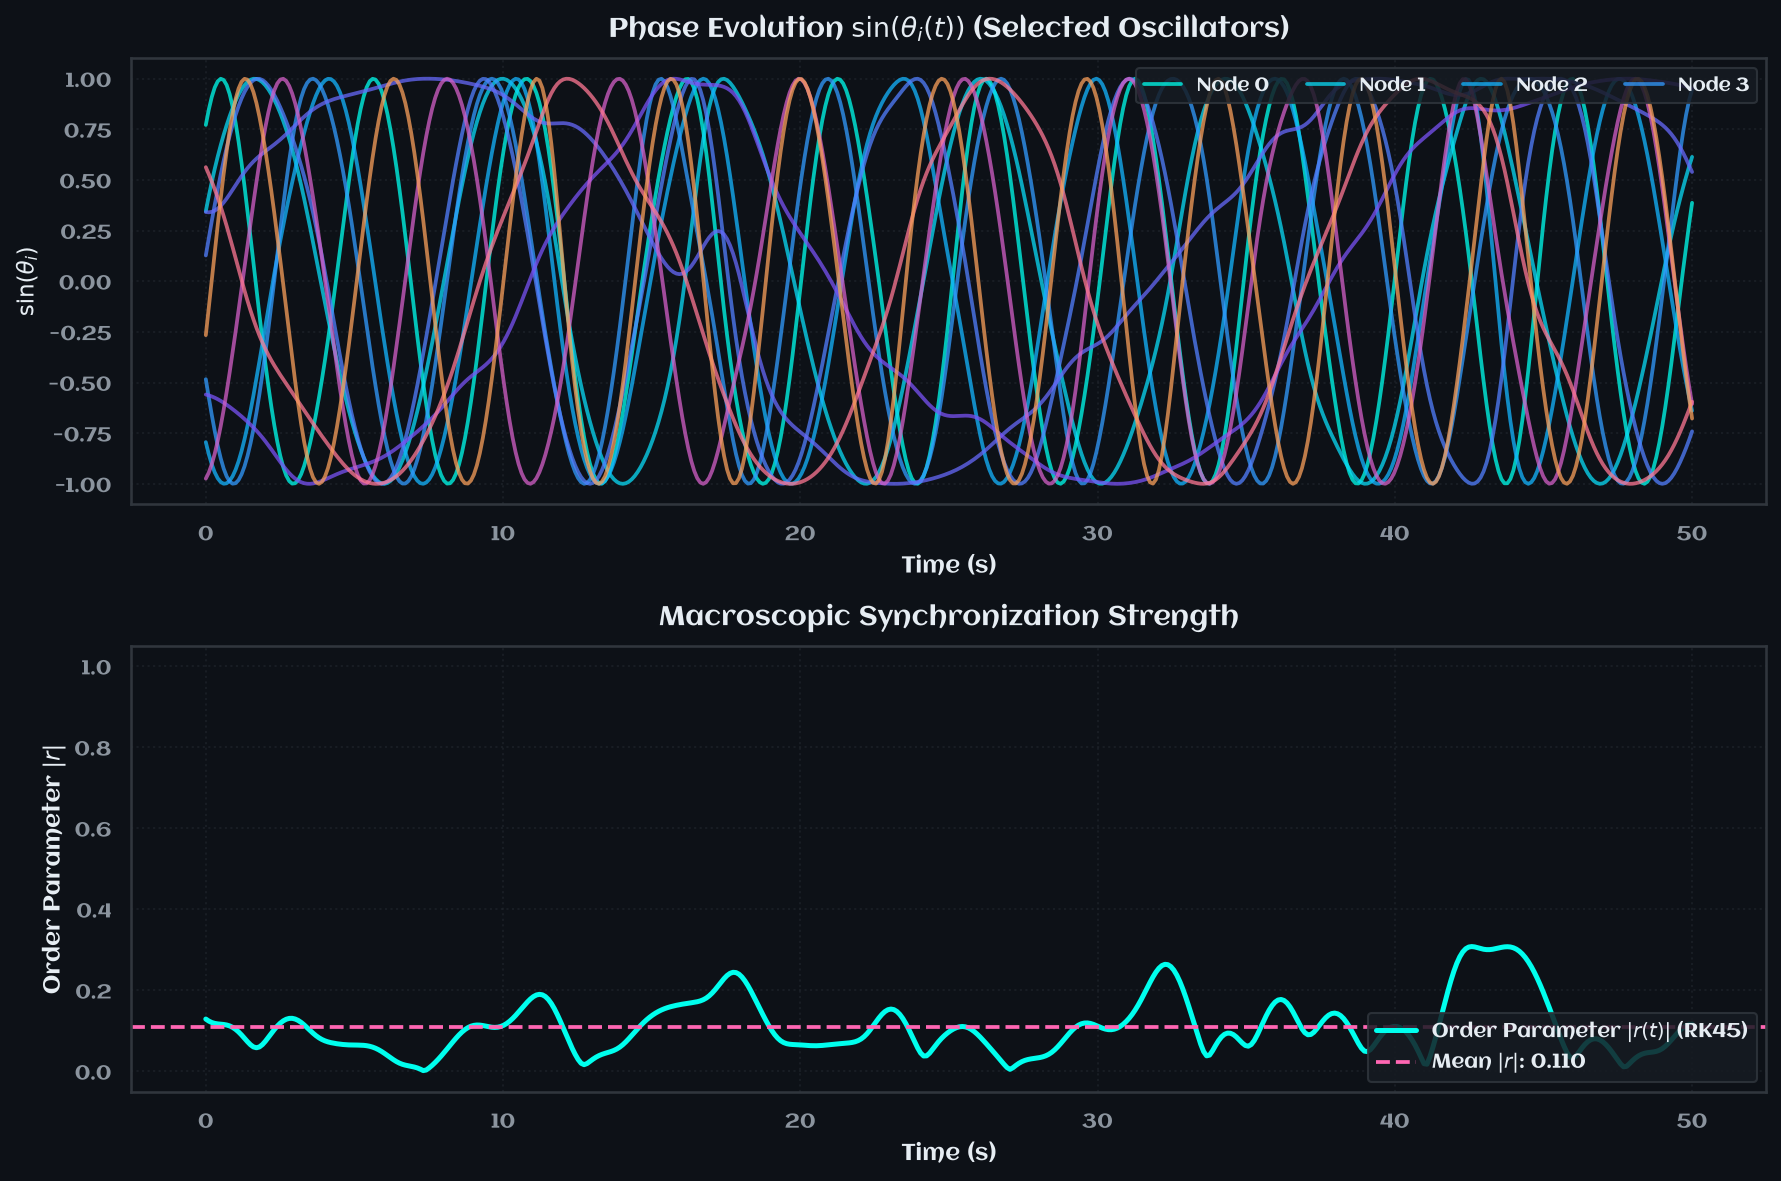


 📊 Classic Solver Statistics:
  Mean |r|: 0.1101
  Std |r|: 0.0701
  Max |r|: 0.3079
  Min |r|: 0.0018


In [4]:
# Compute order parameter
r_classic = compute_order_parameter(theta_classic)

# Plot
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# Top: First 10 oscillators using cyclic phase colormap for high distinguishability
palette_10 = [PHASE_CMAP(i / 10.0) for i in range(min(10, N))]
for i in range(min(10, N)):
    axes[0].plot(
        t_eval,
        np.sin(theta_classic[:, i]),
        color=palette_10[i],
        alpha=0.75,
        linewidth=1.8,
        label=f"Node {i}" if i < 4 else "",
    )
axes[0].set_title("Phase Evolution $\sin(\\theta_i(t))$ (Selected Oscillators)", fontsize=13, fontweight="bold")
axes[0].set_ylabel("$\sin(\\theta_i)$", fontsize=11)
axes[0].set_xlabel("Time (s)", fontsize=11)
axes[0].legend(ncol=4, fontsize="small", loc="upper right")
_apply_aclonica_font(axes[0])

# Bottom: Order parameter
axes[1].plot(t_eval, r_classic, color=SOLVER_COLORS["rk45"], linewidth=2.4, label="Order Parameter $|r(t)|$ (RK45)")
mean_r = np.mean(r_classic)
axes[1].axhline(
    mean_r,
    color=PROJECT_COLORS["pink_vibrant"],
    linestyle="--",
    linewidth=1.8,
    label=f"Mean $|r|$: {mean_r:.3f}",
)
axes[1].set_title("Macroscopic Synchronization Strength", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Time (s)", fontsize=11)
axes[1].set_ylabel("Order Parameter $|r|$", fontsize=11)
axes[1].set_ylim(-0.05, 1.05)
axes[1].legend(loc="lower right")
_apply_aclonica_font(axes[1])

plt.tight_layout()
plt.show()

# Stats
print(f"\n 📊 Classic Solver Statistics:")
print(f"  Mean |r|: {np.mean(r_classic):.4f}")
print(f"  Std |r|: {np.std(r_classic):.4f}")
print(f"  Max |r|: {np.max(r_classic):.4f}")
print(f"  Min |r|: {np.min(r_classic):.4f}")

## 3️⃣ Geometric Algebra Rotor Solver
Oscillators encoded as rotors in $\operatorname{Cl}(2)$ even subalgebra. Requires `clifford` package.

In [5]:
if not CLIFFORD_AVAILABLE:
    print("⚠️ Skipping RotorSolver demo - clifford not installed")
else:
    print("🧭 Initializing RotorSolver in Cl(2)...")

    # Create rotor solver with same parameters
    rotor_solver = RotorSolver(n_oscillators=N, dim=2, seed=seed)
    print(f"  - Oscillators: {rotor_solver.N}")
    print(f"  - GA dimension: Cl({rotor_solver.dim})")
    print(f"  - Rotation plan: {rotor_solver.B_plane}")

    # Run simulation
    print("\n👟 Running rotor simulation...")
    t_rotor, theta_rotor = rotor_solver.simulate(
        K=K,
        t_eval=t_eval,
        dt_internal=0.001,
        enforce_nyquist=True
    )
    print(f"✅ Rotor solver completed: {theta_rotor.shape}")

🧭 Initializing RotorSolver in Cl(2)...
  - Oscillators: 50
  - GA dimension: Cl(2)
  - Rotation plan: (1^e12)

👟 Running rotor simulation...
✅ Rotor solver completed: (500, 50)


<>:48: SyntaxWarning: invalid escape sequence '\s'
<>:54: SyntaxWarning: invalid escape sequence '\o'
<>:48: SyntaxWarning: invalid escape sequence '\s'
<>:54: SyntaxWarning: invalid escape sequence '\o'
/var/folders/ns/5plm23416m58x94bms_cdd9r0000gn/T/ipykernel_271/1951017244.py:48: SyntaxWarning: invalid escape sequence '\s'
  axes[0].set_ylabel('$\sin(\\theta_i)$', fontsize=11)
/var/folders/ns/5plm23416m58x94bms_cdd9r0000gn/T/ipykernel_271/1951017244.py:54: SyntaxWarning: invalid escape sequence '\o'
  axes[1].plot(t_rotor, r_rotor_fair, color=SOLVER_COLORS['rotor'], linestyle='--', linewidth=2.4, label='GA Rotor ($\operatorname{Cl}_{2,0}$)')


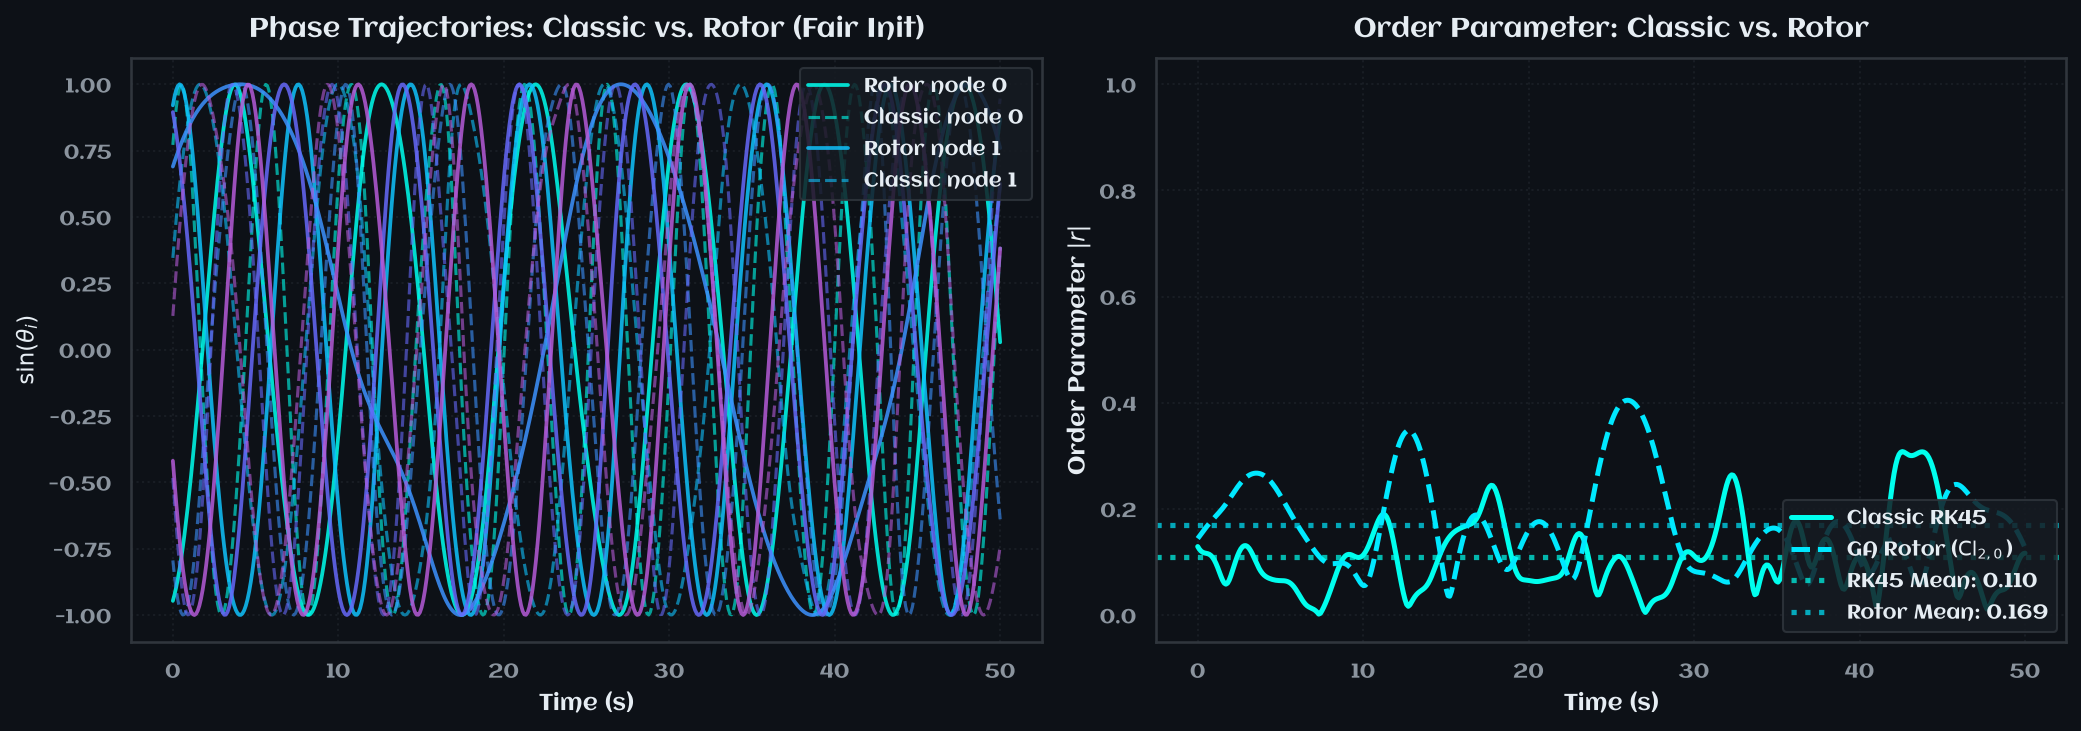


📊 Synchronization Comparison (Fair Initialization):
Metric                            Classic   GA Rotor
--------------------------------------------------
Mean |r|                           0.1101     0.1692
Std |r|                            0.0701     0.0853
Final |r|                          0.1166     0.1267


In [6]:
if CLIFFORD_AVAILABLE:
    # Create new rotor solver WITH matching initial conditions
    rotor_solver_fair = RotorSolver(n_oscillators=N, dim=2, seed=seed)

    # Helper to initialize rotors from explicit phases
    def init_rotors_from_phases(solver, initial_phases):
        """Reset rotor states to match given phase array."""
        solver.rotors = [np.exp(-solver.B_plane * p / 2) for p in initial_phases]

    init_rotors_from_phases(rotor_solver_fair, theta_classic[0, :])

    # Run with smaller timestep for stability
    t_rotor, theta_rotor = rotor_solver_fair.simulate(
        K=K,
        t_eval=t_eval,
        dt_internal=0.0005,
        enforce_nyquist=True
    )

    # Track synchronization strength directly from simulation phases
    r_rotor_fair = compute_order_parameter(theta_rotor)

    # Re-compare
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Left: Phases comparison
    rotor_sample_colors = [PHASE_CMAP(i / 6.0) for i in range(min(5, N))]
    for i in range(min(5, N)):
        axes[0].plot(
            t_rotor,
            np.sin(theta_rotor[:, i]),
            color=rotor_sample_colors[i],
            alpha=0.85,
            linewidth=1.8,
            label=f'Rotor node {i}' if i < 2 else '',
        )
        axes[0].plot(
            t_eval,
            np.sin(theta_classic[:, i]),
            color=rotor_sample_colors[i],
            alpha=0.6,
            linestyle='--',
            linewidth=1.5,
            label=f'Classic node {i}' if i < 2 else '',
        )
    axes[0].set_title('Phase Trajectories: Classic vs. Rotor (Fair Init)', fontsize=13, fontweight='bold')
    axes[0].set_xlabel('Time (s)', fontsize=11)
    axes[0].set_ylabel('$\sin(\\theta_i)$', fontsize=11)
    axes[0].legend(loc='upper right')
    _apply_aclonica_font(axes[0])

    # Right: Order parameter
    axes[1].plot(t_eval, r_classic, color=SOLVER_COLORS['rk45'], linewidth=2.4, label='Classic RK45')
    axes[1].plot(t_rotor, r_rotor_fair, color=SOLVER_COLORS['rotor'], linestyle='--', linewidth=2.4, label='GA Rotor ($\operatorname{Cl}_{2,0}$)')
    axes[1].axhline(np.mean(r_classic), color=SOLVER_COLORS['rk45'], linestyle=':', alpha=0.7, label=f"RK45 Mean: {np.mean(r_classic):.3f}")
    axes[1].axhline(np.mean(r_rotor_fair), color=SOLVER_COLORS['rotor'], linestyle=':', alpha=0.7, label=f"Rotor Mean: {np.mean(r_rotor_fair):.3f}")
    axes[1].set_title('Order Parameter: Classic vs. Rotor', fontsize=13, fontweight='bold')
    axes[1].set_xlabel('Time (s)', fontsize=11)
    axes[1].set_ylabel('Order Parameter $|r|$', fontsize=11)
    axes[1].set_ylim(-0.05, 1.05)
    axes[1].legend(loc='lower right')
    _apply_aclonica_font(axes[1])

    plt.tight_layout()
    plt.show()

    # Stats table
    print(f"\n📊 Synchronization Comparison (Fair Initialization):")
    print(f"{'Metric':<30} {'Classic':>10} {'GA Rotor':>10}")
    print(f"{'-'*50}")
    print(f"{'Mean |r|':<30} {np.mean(r_classic):>10.4f} {np.mean(r_rotor_fair):>10.4f}")
    print(f"{'Std |r|':<30} {np.std(r_classic):>10.4f} {np.std(r_rotor_fair):>10.4f}")
    print(f"{'Final |r|':<30} {r_classic[-1]:>10.4f} {r_rotor_fair[-1]:>10.4f}")

### Diagnostic Test 1: Check Convergence Speed

In [7]:
# When does each solver reach 90% of its final sync?
if CLIFFORD_AVAILABLE:
    # Find when r exceeds 90% of final value
    target_fraction = 0.9

    classic_target = np.mean(r_classic) * target_fraction
    rotor_target = np.mean(r_rotor_fair) * target_fraction

    classic_idx = np.where(r_classic >= classic_target)[0][0] if np.any(r_classic >= classic_target) else None
    rotor_idx = np.where(r_rotor_fair >= rotor_target)[0][0] if np.any(r_rotor_fair >= rotor_target) else None

    print(f"📈 Convergence Time (90% of final |r|):")
    if classic_idx:
        print(f"  Classic RK45: {t_eval[classic_idx]:.2f}s (step {classic_idx})")
    if rotor_idx:
        print(f"  GA Rotor: {t_rotor[rotor_idx]:.2f}s (step {rotor_idx})")

    # Compare variance (how much does |r| fluctuate?)
    print(f"\n📊 Temporal Variability:")
    print(f"  Classic std(|r|): {np.std(r_classic):.4f}")
    print(f"  Rotor std(|r|): {np.std(r_rotor_fair):.4f}")
    print(f"  Variance ratio (Classic/Rotor): {np.var(r_classic)/np.var(r_rotor_fair):.2f}x")

📈 Convergence Time (90% of final |r|):
  GA Rotor: 0.20s (step 2)

📊 Temporal Variability:
  Classic std(|r|): 0.0701
  Rotor std(|r|): 0.0853
  Variance ratio (Classic/Rotor): 0.67x


### Diagnostic Test 2: Reduce dt Further (Stability Check)

🔬 Running dt sensitivity test (optimized)...
✅ Simulation complete. Computing order parameters...


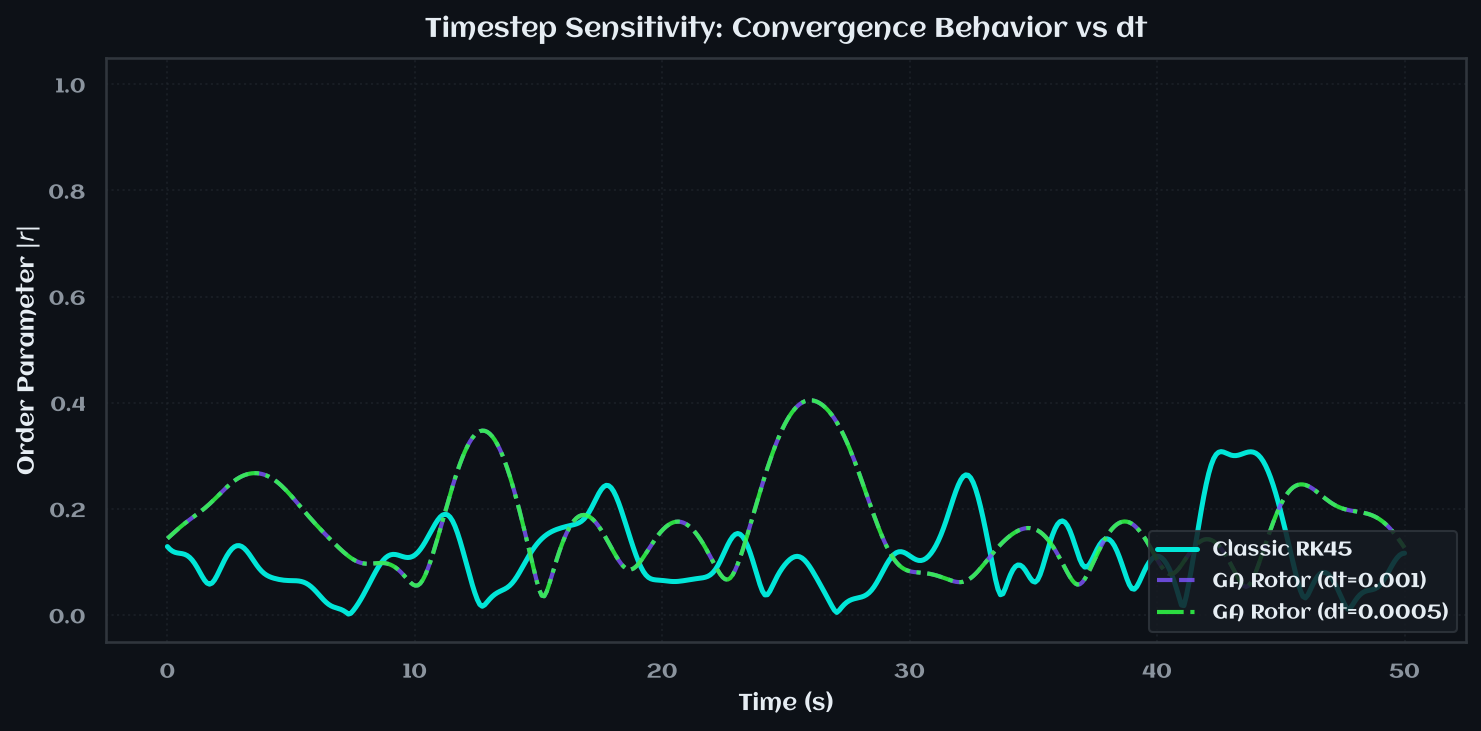


Final |r| at different timesteps:
  Classic: 0.1166
  Rotor dt=0.001: 0.1267
  Rotor dt=0.0005: 0.1267


In [8]:
if CLIFFORD_AVAILABLE:
    print("🔬 Running dt sensitivity test (optimized)...")

    # Create new rotor solver
    rotor_solver_test = RotorSolver(n_oscillators=N, dim=2, seed=seed)
    init_rotors_from_phases(rotor_solver_test, theta_classic[0, :])

    # Run simulation with smaller timestep
    t_rotor_test, theta_rotor_test = rotor_solver_test.simulate(
        K=K,
        t_eval=t_eval,
        dt_internal=0.0005,
        enforce_nyquist=True
    )

    # Compute order parameter DIRECTLY from stored phases (don't step again!)
    complex_states = np.exp(1j * theta_rotor_test)
    r_rotor_test = np.abs(np.mean(complex_states, axis=1))

    print(f"✅ Simulation complete. Computing order parameters...")

    # Plot comparison
    plt.figure(figsize=(10, 5))
    plt.plot(t_eval, r_classic, color=SOLVER_COLORS['rk45'], linewidth=2.4, label='Classic RK45', alpha=0.9)
    plt.plot(t_rotor, r_rotor_fair, color=PROJECT_COLORS['purple_light'], linestyle='--', linewidth=2.0, label='GA Rotor (dt=0.001)', alpha=0.85)
    plt.plot(t_rotor_test, r_rotor_test, color=PROJECT_COLORS['green_neon'], linestyle='-.', linewidth=2.0, label='GA Rotor (dt=0.0005)', alpha=0.85)
    plt.xlabel('Time (s)', fontsize=11)
    plt.ylabel('Order Parameter $|r|$', fontsize=11)
    plt.title('Timestep Sensitivity: Convergence Behavior vs dt', fontsize=13, fontweight='bold')
    plt.ylim(-0.05, 1.05)
    plt.legend(loc='lower right')
    _apply_aclonica_font(plt.gca())
    plt.tight_layout()
    plt.show()

    print(f"\nFinal |r| at different timesteps:")
    print(f"  Classic: {r_classic[-1]:.4f}")
    print(f"  Rotor dt=0.001: {r_rotor_fair[-1]:.4f}")
    print(f"  Rotor dt=0.0005: {r_rotor_test[-1]:.4f}")

🚀 Testing Fast Euler & Geometric Bivector Torque Rotor Integration...
⏱️ Benchmark Results (200 steps, N=50):
  Standard Euler:   279.40 ms
  Fast Euler:       14.03 ms (19.9x speedup, max diff: 1.57e-10)
  Geometric Torque: 2184.79 ms (max diff: 5.62e+00)


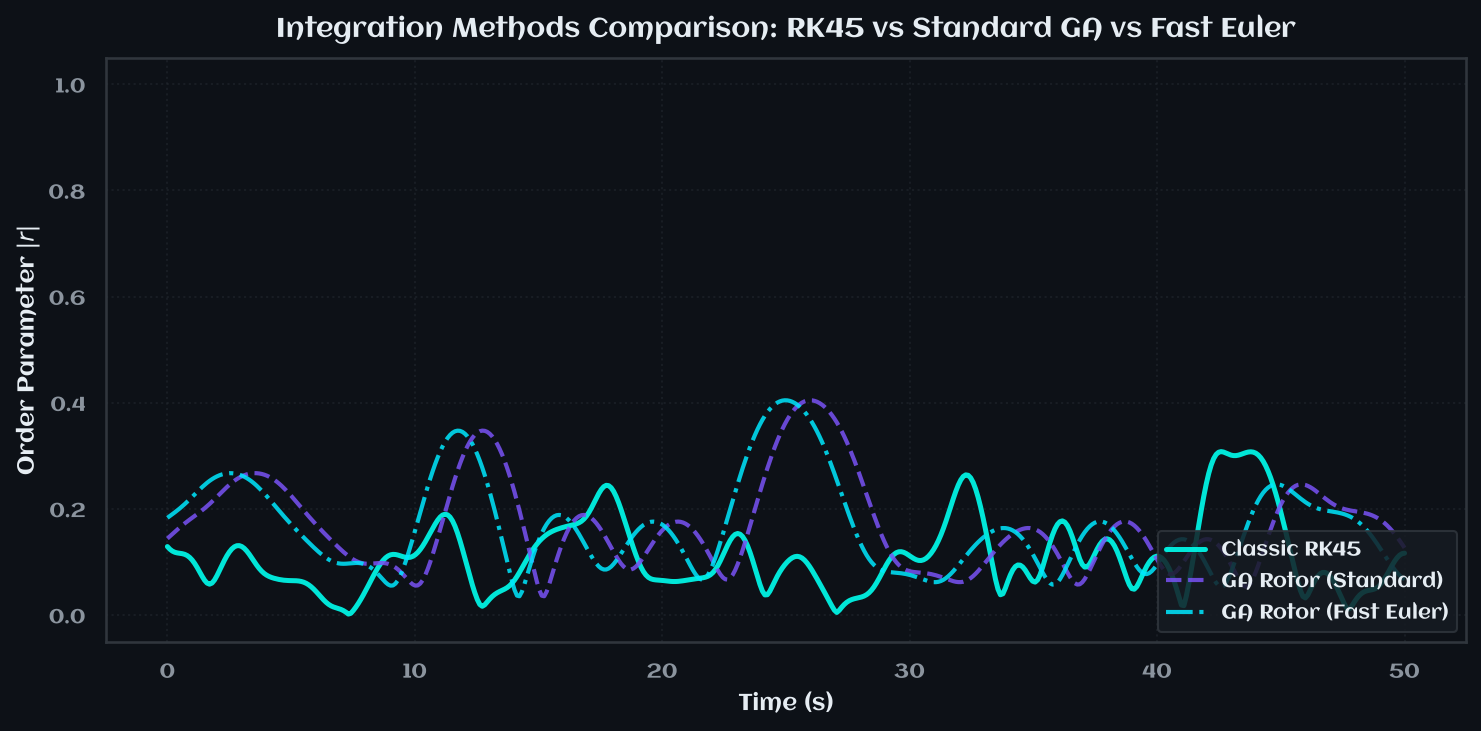

In [9]:
if CLIFFORD_AVAILABLE:
    import time
    print("🚀 Testing Fast Euler & Geometric Bivector Torque Rotor Integration...")

    # Create rotor solvers for comparison
    n_steps = 200
    dt_step = 0.005

    solver_std = RotorSolver(n_oscillators=N, dim=2, seed=seed)
    init_rotors_from_phases(solver_std, theta_classic[0, :])

    solver_fast = RotorSolver(n_oscillators=N, dim=2, seed=seed)
    init_rotors_from_phases(solver_fast, theta_classic[0, :])

    solver_geom = RotorSolver(n_oscillators=N, dim=2, seed=seed)
    init_rotors_from_phases(solver_geom, theta_classic[0, :])

    # 1. Standard Euler benchmark
    t0 = time.time()
    for _ in range(n_steps):
        solver_std.step_euler(K=K, dt=dt_step)
    t_std = time.time() - t0

    # 2. Fast Euler benchmark (vectorized O(N) order parameter)
    t0 = time.time()
    for _ in range(n_steps):
        solver_fast.step_euler_fast(K=K, dt=dt_step)
    t_fast = time.time() - t0

    # 3. Geometric Bivector Torque Euler benchmark (wedge product mean field)
    t0 = time.time()
    for _ in range(n_steps):
        solver_geom.step_euler_geometric(K=K, dt=dt_step)
    t_geom = time.time() - t0

    phases_std = solver_std.extract_phases()
    phases_fast = solver_fast.extract_phases()
    phases_geom = solver_geom.extract_phases()

    diff_fast = np.max(np.abs(phases_std - phases_fast))
    diff_geom = np.max(np.abs(phases_std - phases_geom))

    print(f"⏱️ Benchmark Results ({n_steps} steps, N={N}):")
    print(f"  Standard Euler:   {t_std*1000:.2f} ms")
    print(f"  Fast Euler:       {t_fast*1000:.2f} ms ({t_std/max(t_fast, 1e-6):.1f}x speedup, max diff: {diff_fast:.2e})")
    print(f"  Geometric Torque: {t_geom*1000:.2f} ms (max diff: {diff_geom:.2e})")

    # Run full fast simulation
    t_rotor_fast, theta_rotor_fast = solver_fast.simulate(
        K=K,
        t_eval=t_eval,
        dt_internal=0.001,
        enforce_nyquist=True,
    )
    r_rotor_fast = compute_order_parameter(theta_rotor_fast)

    # Plot comparison
    plt.figure(figsize=(10, 5))
    plt.plot(t_eval, r_classic, color=SOLVER_COLORS['rk45'], linewidth=2.4, label='Classic RK45', alpha=0.9)
    plt.plot(t_rotor, r_rotor_fair, color=PROJECT_COLORS['purple_light'], linestyle='--', linewidth=2.0, label='GA Rotor (Standard)', alpha=0.85)
    plt.plot(t_rotor_fast, r_rotor_fast, color=SOLVER_COLORS['rotor'], linestyle='-.', linewidth=2.0, label='GA Rotor (Fast Euler)', alpha=0.85)
    plt.xlabel('Time (s)', fontsize=11)
    plt.ylabel('Order Parameter $|r|$', fontsize=11)
    plt.title('Integration Methods Comparison: RK45 vs Standard GA vs Fast Euler', fontsize=13, fontweight='bold')
    plt.ylim(-0.05, 1.05)
    plt.legend(loc='lower right')
    _apply_aclonica_font(plt.gca())
    plt.tight_layout()
    plt.show()

### Diagnostic Test 3: Phase Space Portrait

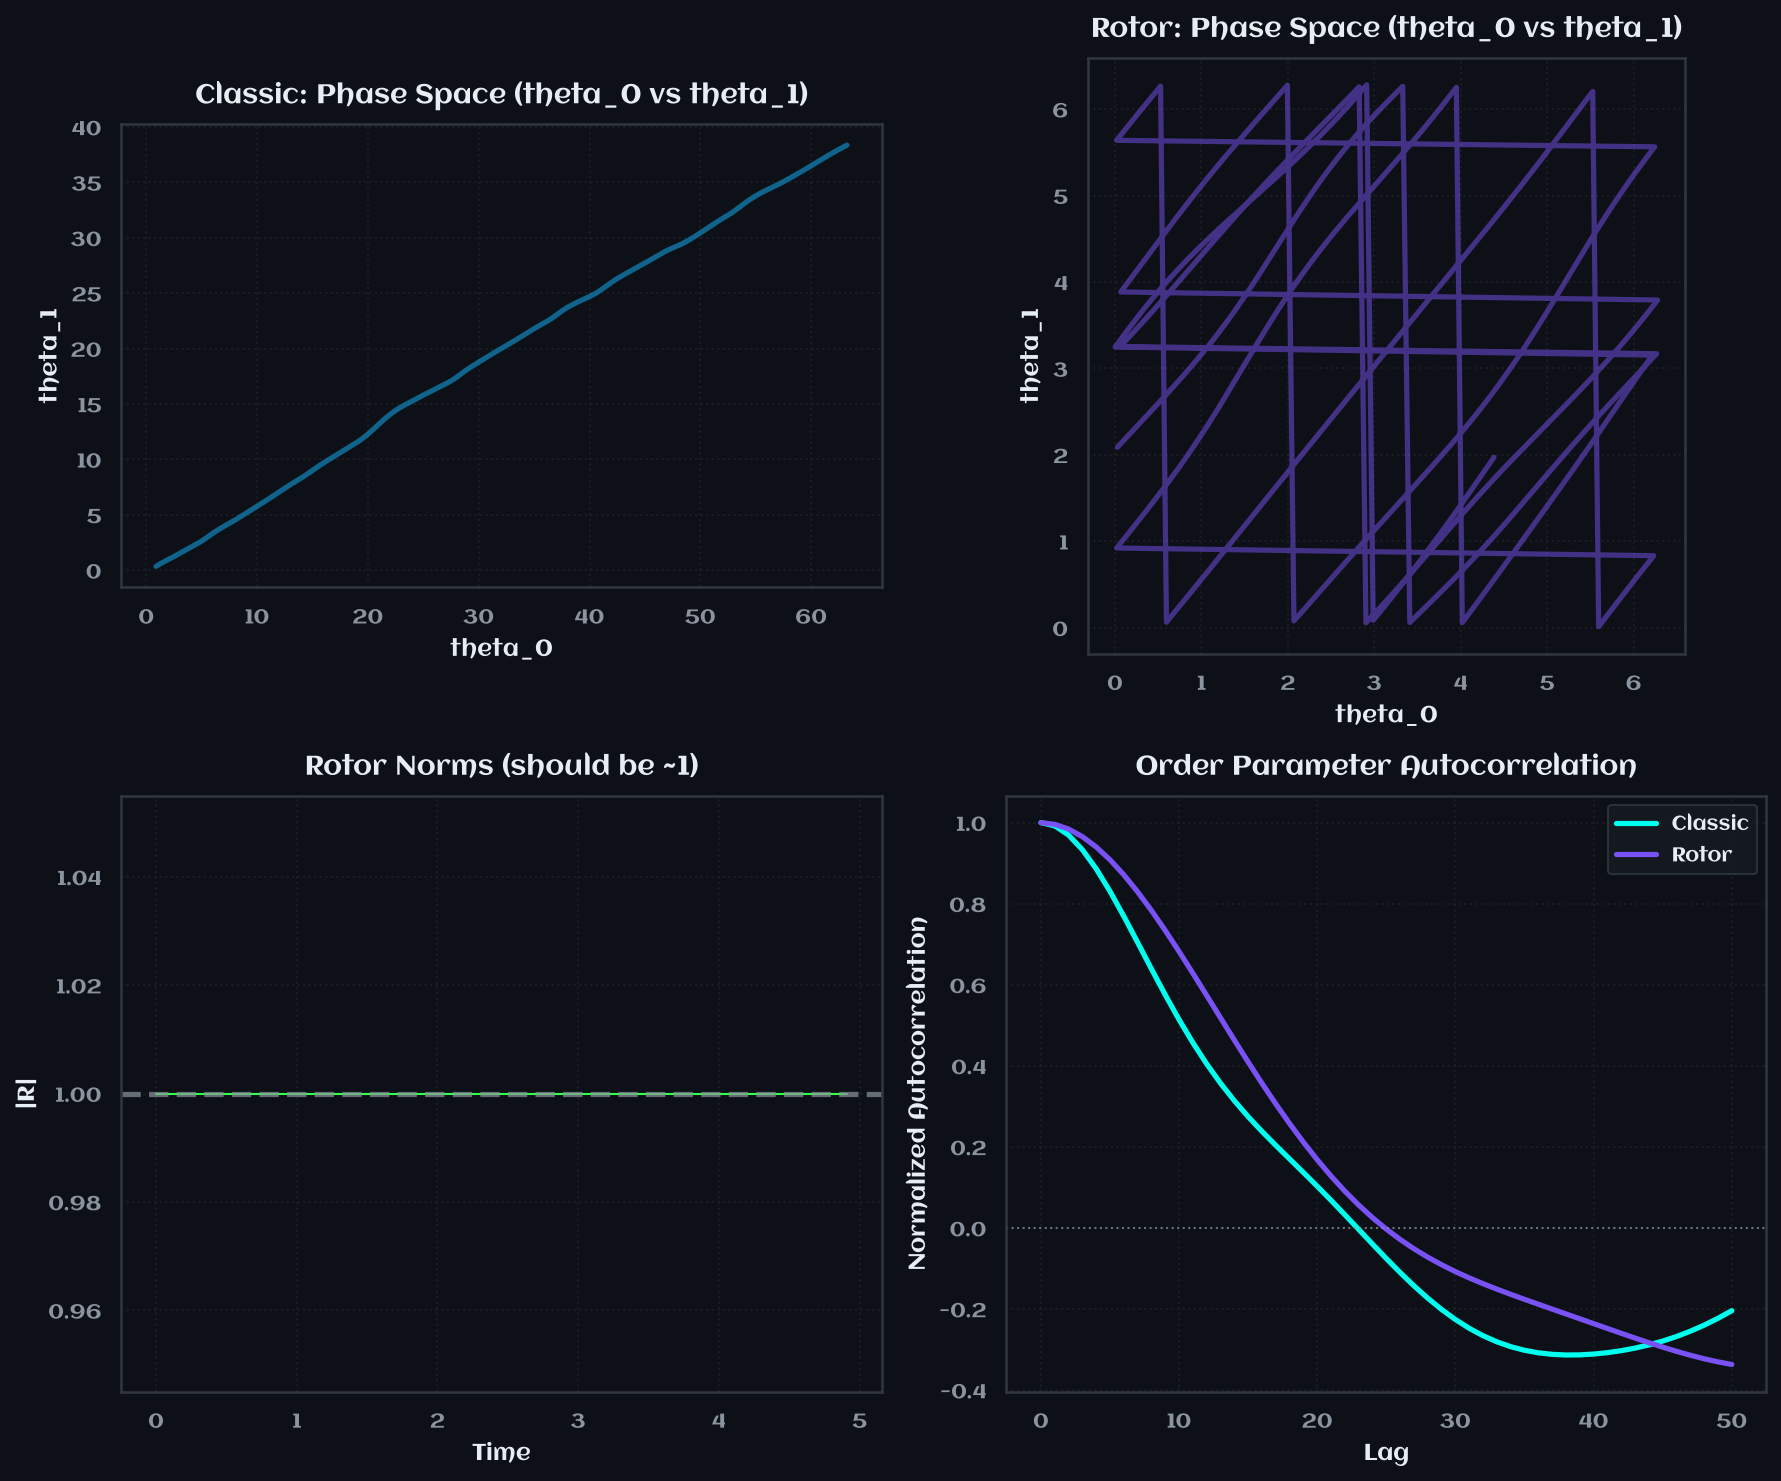

In [10]:
if CLIFFORD_AVAILABLE:
    set_style()
    fig, axes = plt.subplots(2, 2, figsize=(12, 10), facecolor=THEME_BG)

    # Phase space for classic (oscillator 0 vs 1)
    axes[0, 0].plot(
        theta_classic[:, 0], theta_classic[:, 1],
        color=PROJECT_COLORS["blue_light"], alpha=0.5,
    )
    axes[0, 0].set_title("Classic: Phase Space (theta_0 vs theta_1)")
    axes[0, 0].set_xlabel("theta_0")
    axes[0, 0].set_ylabel("theta_1")
    axes[0, 0].set_aspect("equal")

    # Phase space for rotor
    axes[0, 1].plot(
        theta_rotor[:, 0], theta_rotor[:, 1],
        color=PROJECT_COLORS["purple_light"], alpha=0.5,
    )
    axes[0, 1].set_title("Rotor: Phase Space (theta_0 vs theta_1)")
    axes[0, 1].set_xlabel("theta_0")
    axes[0, 1].set_ylabel("theta_1")
    axes[0, 1].set_aspect("equal")

    # Rotor magnitudes over time (should be ~1 for valid rotors)
    rotor_magnitudes = [abs(rotor_solver_fair.rotors[i]) for i in range(len(rotor_solver_fair.rotors))]
    axes[1, 0].plot(
        t_rotor[:len(rotor_magnitudes)], rotor_magnitudes,
        color=PROJECT_COLORS["green_neon"], linewidth=1.0,
    )
    axes[1, 0].axhline(1.0, color=TEXT_MUTED, linestyle="--", alpha=0.7)
    axes[1, 0].set_title("Rotor Norms (should be ~1)")
    axes[1, 0].set_xlabel("Time")
    axes[1, 0].set_ylabel("|R|")

    # Order parameter autocorrelation (centered on lag 0, normalized to 1.0)
    lags_classic, ac_classic = compute_order_parameter_autocorrelation(r_classic, max_lag=50)
    lags_rotor, ac_rotor = compute_order_parameter_autocorrelation(r_rotor_fair, max_lag=50)

    plot_autocorrelation(
        {
            "Classic": (lags_classic, ac_classic),
            "Rotor": (lags_rotor, ac_rotor),
        },
        title="Order Parameter Autocorrelation",
        ax=axes[1, 1],
    )

    plt.tight_layout()
    plt.show()